# Starter analysis

The basics: loading `results/timings.csv`, turning batch totals into per-operation costs,
summarizing replicates, and estimating a growth rate from a log-log fit.
It uses the rows from the worked `example` experiment (`make experiments ... ONLY=example`).

Make your own notebook(s) in `analysis/` for the real analysis; leave this one as a reference.

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

RESULTS = Path("..") / "results" / "timings.csv"
df = pd.read_csv(RESULTS)

# Per-operation cost: every row is a batch of n_ops operations.
df["us_per_op"] = df["total_ns"] / df["n_ops"] / 1_000
for counter in ["comparisons", "nodes_visited", "rotations", "splits", "resizes"]:
    df[f"{counter}_per_op"] = df[counter] / df["n_ops"]

df[["experiment", "code_version", "machine_id", "index_type", "operation", "n_keys", "rep", "us_per_op", "comparisons_per_op"]].head()

## Always know which code you're looking at

Rows from before and after a bug fix live in the same file. Filter on `code_version`
(and `machine_id`) before you compare anything.

In [ ]:
df.groupby(["code_version", "machine_id", "experiment"]).size()

In [ ]:
example = df[df["experiment"] == "example"]
if example.empty:
    raise RuntimeError("No 'example' rows yet: run `make experiments MEMBER=you MACHINE=id ONLY=example` first.")
# Pick one code version and one machine to keep the comparison controlled.
version = example["code_version"].iloc[-1]
machine = example["machine_id"].iloc[-1]
example = example[(example["code_version"] == version) & (example["machine_id"] == machine)]

# Summarize replicates with the median and the interquartile range.
summary = (
    example.groupby(["operation", "index_type", "n_keys"])["us_per_op"]
    .describe(percentiles=[0.25, 0.5, 0.75])[["count", "25%", "50%", "75%"]]
    .rename(columns={"50%": "median"})
)
summary

## Cost vs. n on log-log axes

On log-log axes, cost proportional to $n^k$ is a straight line with slope $k$:
roughly 0 for constant time, 1 for linear time, and slowly bending for $\log n$.

In [ ]:
hits = example[example["operation"] == "point_hit"]
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.lineplot(data=hits, x="n_keys", y="us_per_op", hue="index_type",
             estimator="median", errorbar=("pi", 50), marker="o", ax=ax)
ax.set(xscale="log", yscale="log", xlabel="keys in index (n)",
       ylabel="µs per lookup (median, IQR band)", title=f"Point lookups (hits), code {version}")
ax.legend(title="index", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()

## Estimating the growth exponent

Fit $\log_{10}(\text{cost}) = a + k \log_{10}(n)$ to the per-n medians. With only three sizes
this is a rough estimate; your experiments should use more sizes, and you should report an
interval for $k$ (e.g. bootstrap over replicates), not just a point estimate.

In [ ]:
rows = []
for index_type, g in hits.groupby("index_type"):
    med = g.groupby("n_keys")["us_per_op"].median()
    k, a = np.polyfit(np.log10(med.index), np.log10(med.values), 1)
    rows.append({"index_type": index_type, "slope_k": round(k, 2)})
pd.DataFrame(rows).sort_values("slope_k")

## Counters vs. timings

Counters (`comparisons_per_op`, `nodes_visited_per_op`, ...) are deterministic, so they have no
replicate-to-replicate noise and are identical on every machine. Plot them against theory,
e.g. $\log_2 n$ for a balanced binary tree. The reference indexes (`ref_*`) don't count operations.

In [ ]:
counted = hits[hits["comparisons"].notna()]
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.lineplot(data=counted, x="n_keys", y="comparisons_per_op", hue="index_type", marker="o", ax=ax)
n = np.array(sorted(counted["n_keys"].unique()))
ax.plot(n, np.log2(n), "k--", label="log2(n)")
ax.set(xscale="log", yscale="log", xlabel="keys in index (n)", ylabel="comparisons per lookup")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()

n_keys
1000        466.116
3000       1433.260
10000      4763.958
30000     13955.478
60000     25821.378
114000    43514.996
Name: comparisons_per_lookup, dtype: float64


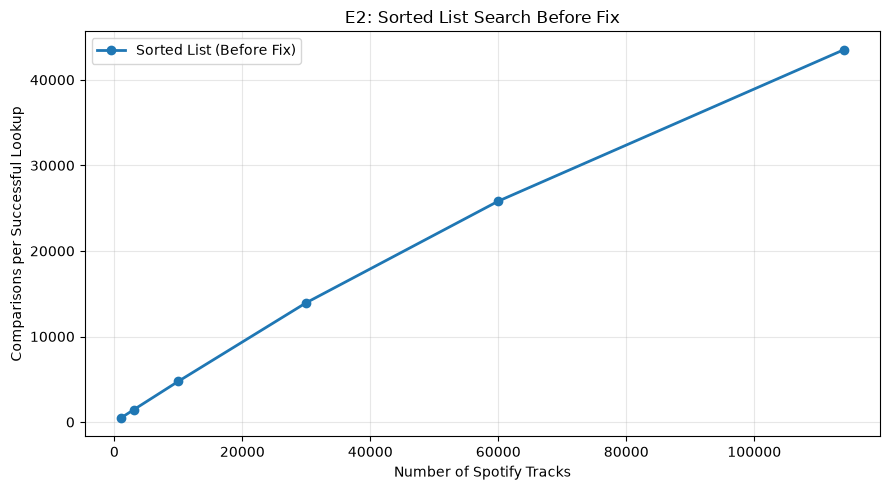

In [1]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Find the project folder
root = Path.cwd()
if not (root / "results" / "timings.csv").exists():
    root = root.parent

# Read your experiment measurements
df = pd.read_csv(root / "results" / "timings.csv")

# Select your original E2 sorted-list results
e2 = df[
    (df["experiment"] == "E2_point_lookup") &
    (df["session_id"] == "26d932c399ee") &
    (df["code_version"] == "c2406c6") &
    (df["index_type"] == "sorted_list") &
    (df["operation"] == "point_hit")
].copy()

# Calculate comparisons per lookup
e2["comparisons_per_lookup"] = (
    e2["comparisons"] / e2["n_ops"]
)

# Find the median over five repetitions
summary = (
    e2.groupby("n_keys")["comparisons_per_lookup"]
    .median()
    .sort_index()
)

print(summary)

# Create the graph
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    summary.index,
    summary.values,
    marker="o",
    linewidth=2,
    label="Sorted List (Before Fix)"
)

ax.set_xlabel("Number of Spotify Tracks")
ax.set_ylabel("Comparisons per Successful Lookup")
ax.set_title("E2: Sorted List Search Before Fix")
ax.legend()
ax.grid(True, alpha=0.3)

fig.tight_layout()

# Save the graph for the incident report
figure_dir = root / "analysis" / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figure_dir / "INC01_E2_sorted_list_before.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


Before-fix session: 26d932c399ee
After-fix session: 61015bb37183
After-fix code version: 3c45879

Before fix:
n_keys
1000        466.116
3000       1433.260
10000      4763.958
30000     13955.478
60000     25821.378
114000    43514.996
Name: per_lookup, dtype: float64

After fix:
n_keys
1000      10.992
3000      12.618
10000     14.238
30000     15.830
60000     16.754
114000    17.536
Name: per_lookup, dtype: float64


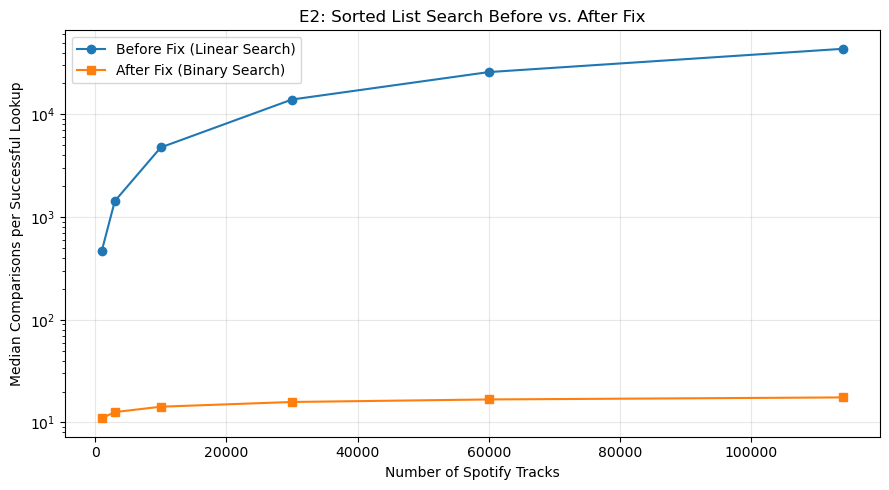

In [1]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Find your project folder
root = Path.cwd()
if not (root / "results" / "timings.csv").exists():
    root = root.parent

# Load experiment measurements
df = pd.read_csv(root / "results" / "timings.csv")

# Select successful sorted-list lookups from E2
e2 = df[
    (df["experiment"] == "E2_point_lookup") &
    (df["index_type"] == "sorted_list") &
    (df["operation"] == "point_hit")
].copy()

# Your original E2 benchmark session
before_id = "26d932c399ee"
before = e2[e2["session_id"] == before_id].copy()

# Find the latest E2 run using the fixed code
after_candidates = e2[
    (e2["session_id"] != before_id) &
    (e2["code_version"] != "c2406c6")
]

if before.empty or after_candidates.empty:
    raise ValueError(
        "Could not find both before-fix and after-fix E2 results."
    )

after_id = after_candidates.iloc[-1]["session_id"]
after = e2[e2["session_id"] == after_id].copy()

print("Before-fix session:", before_id)
print("After-fix session:", after_id)
print("After-fix code version:", after.iloc[-1]["code_version"])

# Calculate comparisons per successful lookup
before["per_lookup"] = before["comparisons"] / before["n_ops"]
after["per_lookup"] = after["comparisons"] / after["n_ops"]

before_summary = before.groupby("n_keys")["per_lookup"].median().sort_index()
after_summary = after.groupby("n_keys")["per_lookup"].median().sort_index()

print("\nBefore fix:")
print(before_summary)

print("\nAfter fix:")
print(after_summary)

# Create the comparison graph
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    before_summary.index,
    before_summary.values,
    marker="o",
    label="Before Fix (Linear Search)"
)

ax.plot(
    after_summary.index,
    after_summary.values,
    marker="s",
    label="After Fix (Binary Search)"
)

ax.set_xlabel("Number of Spotify Tracks")
ax.set_ylabel("Median Comparisons per Successful Lookup")
ax.set_title("E2: Sorted List Search Before vs. After Fix")

# Log scale makes large and small values visible together
ax.set_yscale("log")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()

# Save the graph
figure_dir = root / "analysis" / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figure_dir / "INC01_E2_before_after.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

        resizes      build_ns     build_ms
n_keys                                    
1000        2.0  1.101083e+06     1.101083
3000        4.0  3.464958e+06     3.464958
10000      13.0  2.488775e+07    24.887750
30000      37.0  2.002297e+08   200.229709
60000      68.0  7.793628e+08   779.362834
114000    117.0  2.993167e+09  2993.166543


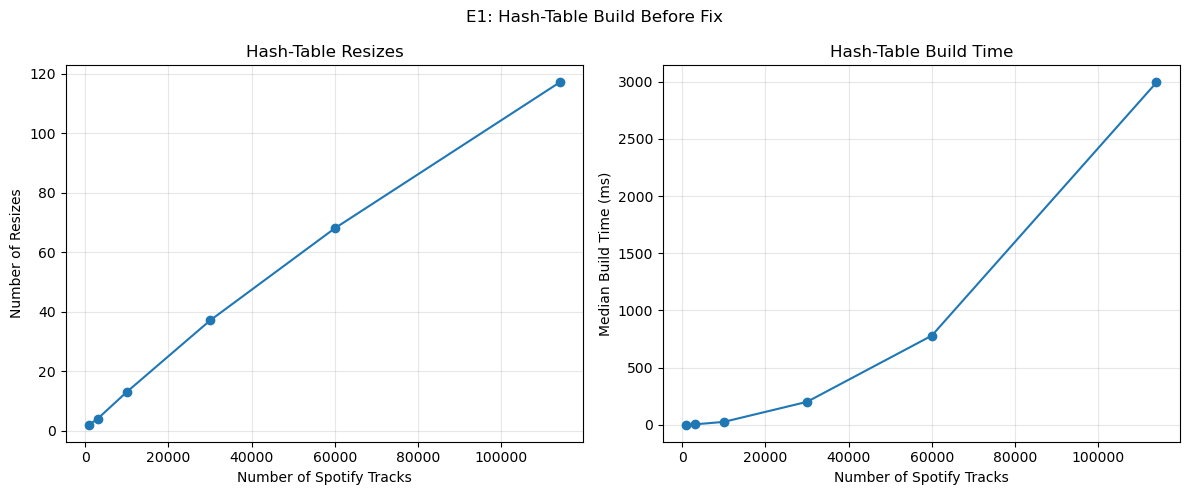

In [2]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Find results/timings.csv
root = Path.cwd()
while not (root / "results" / "timings.csv").exists():
    if root == root.parent:
        raise FileNotFoundError("Could not find timings.csv")
    root = root.parent

df = pd.read_csv(root / "results" / "timings.csv")

# Use only the original E1 hash-table results
e1 = df[
    (df["experiment"] == "E1_build") &
    (df["index_type"] == "hash_table") &
    (df["session_id"] == "54f480364efc") &
    (df["code_version"] == "31da8dc")
].copy()

if e1.empty:
    raise ValueError("Original E1 measurements not found")

# Calculate median results
summary = e1.groupby("n_keys").agg(
    resizes=("resizes", "median"),
    build_ns=("total_ns", "median")
).sort_index()

summary["build_ms"] = summary["build_ns"] / 1_000_000

print(summary)

# Create two graphs in one figure
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(summary.index, summary["resizes"], marker="o")
axes[0].set_title("Hash-Table Resizes")
axes[0].set_xlabel("Number of Spotify Tracks")
axes[0].set_ylabel("Number of Resizes")
axes[0].grid(True, alpha=0.3)

axes[1].plot(summary.index, summary["build_ms"], marker="o")
axes[1].set_title("Hash-Table Build Time")
axes[1].set_xlabel("Number of Spotify Tracks")
axes[1].set_ylabel("Median Build Time (ms)")
axes[1].grid(True, alpha=0.3)

fig.suptitle("E1: Hash-Table Build Before Fix")
fig.tight_layout()

# Save the figure
figure_dir = root / "analysis" / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figure_dir / "INC02_E1_hash_before.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


Before code version: 31da8dc
After code version: eb3808a
        Before build (ms)  After build (ms)  Before resizes  After resizes  \
n_keys                                                                       
1000                 1.10              1.21             2.0            8.0   
3000                 3.46              3.01             4.0            9.0   
10000               24.89             11.18            13.0           11.0   
30000              200.23             38.47            37.0           13.0   
60000              779.36             85.34            68.0           14.0   
114000            2993.17            133.42           117.0           14.0   

        Speedup  
n_keys           
1000       0.91  
3000       1.15  
10000      2.23  
30000      5.21  
60000      9.13  
114000    22.43  


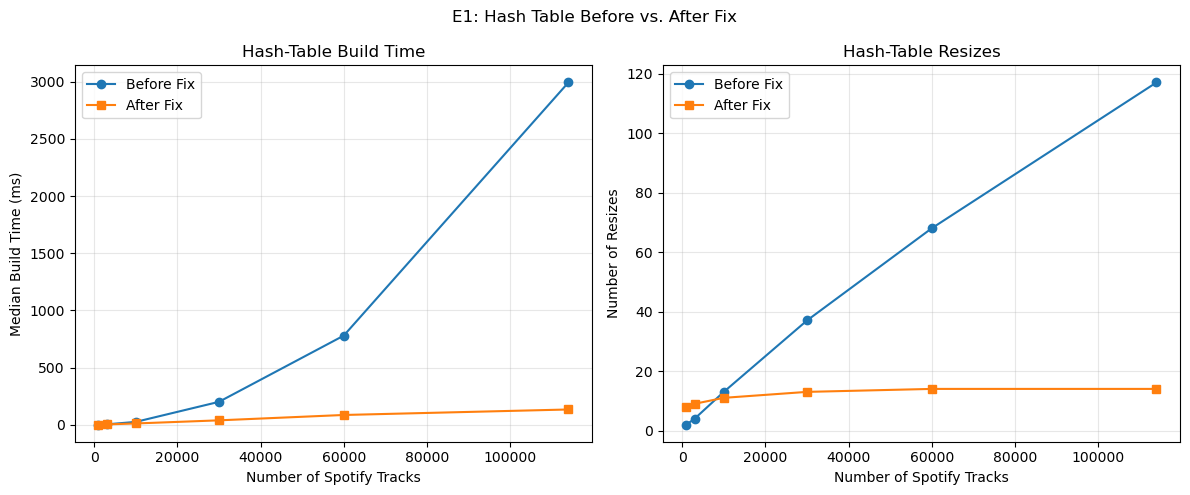

In [3]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Find the results file
root = Path.cwd()
while not (root / "results" / "timings.csv").exists():
    if root == root.parent:
        raise FileNotFoundError("Could not find timings.csv")
    root = root.parent

df = pd.read_csv(root / "results" / "timings.csv")

# Original and corrected E1 benchmark sessions
before_id = "54f480364efc"
after_id = "2558ef9e961c"

# Select hash-table build measurements
e1 = df[
    (df["experiment"] == "E1_build") &
    (df["index_type"] == "hash_table") &
    (df["operation"] == "build")
].copy()

before = e1[e1["session_id"] == before_id].copy()
after = e1[e1["session_id"] == after_id].copy()

if before.empty or after.empty:
    raise ValueError("Could not find both E1 sessions")

print("Before code version:", before["code_version"].iloc[0])
print("After code version:", after["code_version"].iloc[0])

# Calculate median measurements
def summarize(data):
    result = data.groupby("n_keys").agg(
        build_ns=("total_ns", "median"),
        resizes=("resizes", "median")
    ).sort_index()
    result["build_ms"] = result["build_ns"] / 1_000_000
    return result

b = summarize(before)
a = summarize(after)

# Display comparison table
comparison = pd.DataFrame({
    "Before build (ms)": b["build_ms"],
    "After build (ms)": a["build_ms"],
    "Before resizes": b["resizes"],
    "After resizes": a["resizes"]
})

comparison["Speedup"] = (
    comparison["Before build (ms)"] /
    comparison["After build (ms)"]
)

print(comparison.round(2))

# Create before-and-after graphs
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(
    b.index, b["build_ms"],
    marker="o", label="Before Fix"
)
axes[0].plot(
    a.index, a["build_ms"],
    marker="s", label="After Fix"
)
axes[0].set_title("Hash-Table Build Time")
axes[0].set_xlabel("Number of Spotify Tracks")
axes[0].set_ylabel("Median Build Time (ms)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    b.index, b["resizes"],
    marker="o", label="Before Fix"
)
axes[1].plot(
    a.index, a["resizes"],
    marker="s", label="After Fix"
)
axes[1].set_title("Hash-Table Resizes")
axes[1].set_xlabel("Number of Spotify Tracks")
axes[1].set_ylabel("Number of Resizes")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

fig.suptitle("E1: Hash Table Before vs. After Fix")
fig.tight_layout()

# Save graph
figure_dir = root / "analysis" / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figure_dir / "INC02_E1_before_after.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
